In [27]:
using Flux
using Plots
using TaylorSeries
using Chides
using LinearMaps
using IterativeSolvers
using DifferentialEquations

We will use Taylor coefficients as our degrees of freedom. For example if we want to represent the function $a(t)$ we will do so by the coefficients in the polynomial

$$
a(t) = \sum_{j=0}^{m} \frac{1}{j!} \frac{d^{j}a(t)}{d t^{j}}
$$

We will consider the ordinary differential equation

$$
\frac{d}{dt} \left(\begin{array}{c}
u\\
v
    \end{array} \right) = a(t)\left(\begin{array}{cc}
0 & -1\\
1 & 0
\end{array} \right) \left(\begin{array}{c}
u\\
v
\end{array} \right) \equiv A w, 
$$

with initial data $u= 1, \, v=0$.

The method we will use is based on solving a linear system of equations

$$
y + \sum_{j=1}^{m} (-1)^j c_j \Delta t^j F_j(y) = b, 
$$

where $\Delta t$ is the timestep, $F_j(y)$ are linear operators and the coefficients $c_j$ are 

$$
c_j = \frac{m! (2m-j)!}{(2m)! (m-j)!}.
$$

Specifically the linear operators $F_j(y)$ are defined to be mappings from function values to Taylor coefficients, i.e.

$$
F_j(y) = \frac{1}{j!} \frac{d^j y}{d t^j}.
$$

We define functions that takes the solution and returns the linear operators $F_j(y)$.

In [28]:
function y_to_F(w,A,a_tay,m)
    Y = zeros(length(w),m+1)
    Y[:,1+0] .= w
    for j = 0:m-1
        yjp = zeros(size(w))
        for i = 0:j
            yjp .+= (a_tay[1+j-i])*A*Y[:,1+i]
        end
        Y[:,2+j] .= 1/(1+j)*yjp
    end
    return Y[:,2:m+1],Y
end;

We also define a function to compute the right hand side in the linear system of equations.

In [29]:
function compute_b(y,F,c,dt,m)
    b = c[1]*y
    dft = dt;
    for j = 1:m
        b .= b .+ dft*F[:,j]*c[1+j]
        dft = dft*dt
    end  
    return b
end;

This is the function that defines the matrix (free) in the linear system of equations.

In [30]:
function Ay(y,A,m,c,dt,a_tay)
    F, = y_to_F(y,A,a_tay,m)
    F1sum = zeros(length(y))
    df = -1.0;
    dft = dt;
    for j = 1:m
        F1sum .= F1sum .+ dft*df*F[:,j]*c[1+j]
        df *= -1.0
        dft = dft*dt
    end 
    return y .+ F1sum
end;
Aycb(z) = Ay(z,A,m,c,dt,a_tay);

In [31]:
tend = 6*pi
nt = 8
dt = tend/nt
m = 8
y0 = [1.0,0.0];
Y = zeros(length(y0),m+1,nt+1)
T = LinRange(0,tend,nt+1)

# The variable coefficient
a_tay = zeros(m+1)
affine(a) = a + Taylor1(typeof(a),m+3)
idfun(x) = 2.0 + sin(x)

c = zeros(m+1)
for j = 0:m
c[1+j] = (factorial(m)*factorial(2*m-j))/(factorial(2*m)*factorial(m-j))
end
A = [0.0 -1.0
    1.0 0.0]

# Definr the "matrix"
M = length(y0)
HM_MAT = LinearMap(Aycb,M)


t = 0.0
# This is to be replaced by a more efficient way to compute / handle the variable coefficient
tl = affine(t)
Ul = idfun(tl)
a_tay[1:m+1] .= Ul[0:m]   
F0,Ytay = y_to_F(y0,A,a_tay,m)
Y[:,:,1] .= Ytay
b = compute_b(y0,F0,c,dt,m)

for it = 1:nt
    t = (it-1)*dt
    t = t+dt
    tl = affine(t)
    Ul = idfun(tl)
    a_tay[1:m+1] .= Ul[0:m]   
    y1,history = gmres(HM_MAT,b,reltol=1e-12,log=true)
    # Shuffle timesteps and compute stuff neded in the linear system
    y0 = y1
    F0,Ytay = y_to_F(y0,A,a_tay,m)
    Y[:,:,1+it] .= Ytay
    b = compute_b(y0,F0,c,dt,m)
end

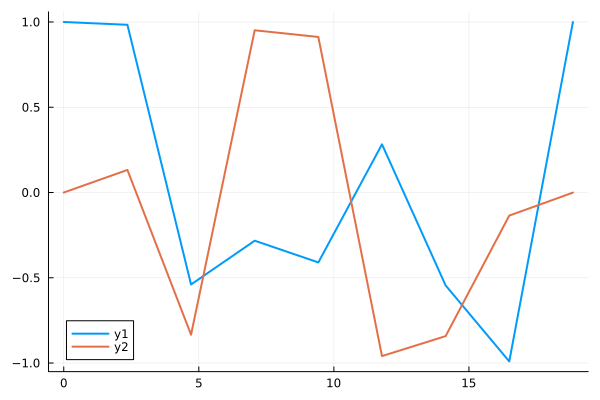

In [32]:
plot(T,Y[:,1,:]',lw=2)

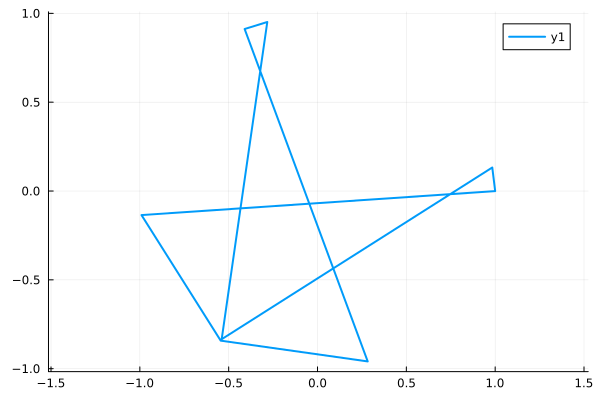

In [33]:
plot(Y[1,1,:],Y[2,1,:],lw=2,aspect_ratio = :equal )

In [34]:
Hmat = zeros(Float64,2*(m+1),2*(m+1))
xl = -1.0
xr = 1.0
xc = 0.0
icase = 0
hermitemap!(Hmat,m,xl,xr,xc,icase)

scale = zeros(Float64,2*(m+1),2*(m+1))
df = 1.0
for i = 0:2*m+1
    scale[1+i,1+i] = df
    df = df*dt
end

function evalhinterp(x,ucof)
    deg_p1 = length(ucof) 
    u = zeros(size(x))
    z = ones(size(x))
    for d = 0:deg_p1-1
        u += ucof[1+d]*z
        z = z.*x
    end
    return u
end ;

In [35]:
function rhside!(du, u, p, t)
    #du = *p*u
    du[1] = -(2.0+sin(t))*u[2]
    du[2] =  (2.0+sin(t))*u[1]
end
u0 = [1.0; 0.0]
tspan = (0.0, tend)
prob = ODEProblem(rhside!, u0, tspan,A)
sol = solve(prob);

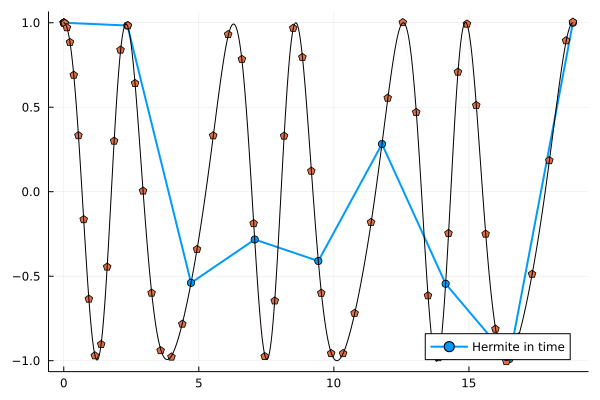

In [36]:
neval = 101

z = collect(LinRange(-0.5,0.5,neval))

pl = plot(T,Y[1,1,:],lw=2,marker=:circle,label = "Hermite in time")
plot!(pl,sol.t,sol[1,:],label=:none,plotdensity = 100,lw=0,marker=:p)
ucof = zeros(2*m+2)
ifield = 1
for i = 1:nt
    u = zeros(Float64,m+1,2)
    #scaletaylorkind!(u,Y[ifield,:,i],Y[ifield,:,i+1],m,dt)
    #ucof .= reshape(u,(2*m+2,1))[:]
    ucof[1:m+1] = scale[1:m+1,1:m+1]*Y[ifield,:,i]
    ucof[m+2:2*m+2] = scale[1:m+1,1:m+1]*Y[ifield,:,i+1]
    uint = Hmat*ucof
    uplot = evalhinterp(z,uint)
    plot!(pl,T[i] .+ dt*(0.5 .+ z),uplot,color=:black,lw=1,label = :none)
end
display(pl)

Next we sho how a Hermite interpolant can be used to represent the control.

In [21]:
a_ctrl = zeros(m+1,2)
a_ctrl[1,1] = 1.0
a_ctrl[1,2] = -1.0
ucof = zeros(2*m+2) 
ucof[1:m+1] = a_ctrl[:,1]
ucof[m+2:2*m+2] = a_ctrl[:,2]
a_ctrl_I = Hmat*ucof;

In [22]:
dt_ctrl = tend;

In [25]:
tend = 6*pi
nt = 8
dt = tend/nt
y0 = [1.0,0.0];
Y = zeros(length(y0),m+1,nt+1)
T = LinRange(0,tend,nt+1)

a_tay = zeros(m+1)

ctrl_scl = zeros(m+1)
df = 1.0
for i = 0:m
    ctrl_scl[1+i] = df
    df = df/tend
end

t = 0.0
t_int = -0.5 + t/tend

q = 2*m+1
ucof = copy(a_ctrl_I)
extrapolate!(ucof,t_int,q)

a_tay[1:m+1] .= (ctrl_scl.*ucof[1:m+1])   
F0,Ytay = y_to_F(y0,A,a_tay,m)
Y[:,:,1] .= Ytay
b = compute_b(y0,F0,c,dt,m)

for it = 1:nt
    t = it*dt
    t_int = -0.5 + t/tend
    q = 2*m+1
    ucof = copy(a_ctrl_I)
    extrapolate!(ucof,t_int,q)
    a_tay[1:m+1] .= (ctrl_scl.*ucof[1:m+1])   
    y1,history = gmres(HM_MAT,b,reltol=1e-12,log=true)
    # Shuffle timesteps and compute stuff neded in the linear system
    y0 = y1
    F0,Ytay = y_to_F(y0,A,a_tay,m)
    Y[:,:,1+it] .= Ytay
    b = compute_b(y0,F0,c,dt,m)
end

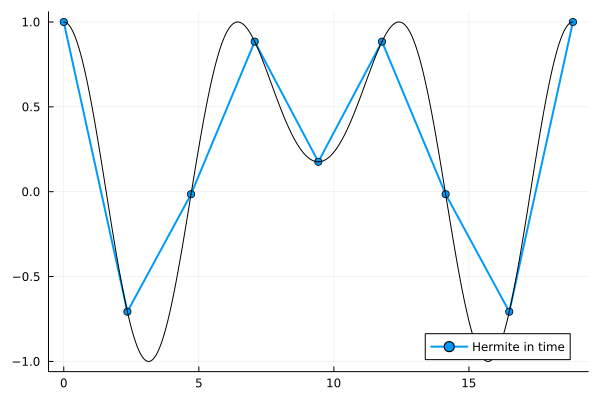

In [26]:
neval = 101

z = collect(LinRange(-0.5,0.5,neval))

pl = plot(T,Y[1,1,:],lw=2,marker=:circle,label = "Hermite in time")
ucof = zeros(2*m+2)
ifield = 1
for i = 1:nt
    u = zeros(Float64,m+1,2)
    ucof[1:m+1] = scale[1:m+1,1:m+1]*Y[ifield,:,i]
    ucof[m+2:2*m+2] = scale[1:m+1,1:m+1]*Y[ifield,:,i+1]
    uint = Hmat*ucof
    uplot = evalhinterp(z,uint)
    plot!(pl,T[i] .+ dt*(0.5 .+ z),uplot,color=:black,lw=1,label = :none)
end
display(pl)